# 2. Découpage des PDF et embeddings

Objectifs : (1) parser et découper les DIC en chunks, (2) choisir un embedding adapté au français financier, (3) stocker les vecteurs **localement dans ChromaDB**.
Chaque choix est **mesuré** (retrieval sur le dataset d'évaluation) plutôt que supposé.

In [1]:
import os, sys, json, time, warnings
warnings.filterwarnings("ignore")
os.environ["TOKENIZERS_PARALLELISM"] = "false"
sys.path.insert(0, os.path.abspath(".."))
import pandas as pd, numpy as np
pd.set_option("display.max_colwidth", 110, "display.width", 200, "display.max_columns", 30)
import gc, torch
from rag.config import *
from rag.ingest import build_chunks, list_pdfs, load_pdf
from rag.evaluation import load_eval, corpus_documents, exact_retrieval, pdf_retrieval, locate_sources, named_query_retrieval
from rag.embeddings import LocalEmbeddings
from rag.store import build_store, get_store, Reranker
ev = load_eval(); cat = json.loads(CATALOG_PATH.read_text(encoding="utf-8"))
print(f"Paramètres retenus : chunk_size={CHUNK_SIZE}, overlap={CHUNK_OVERLAP}, en-tête produit={WITH_HEADER}, top_k={TOP_K}, reranker={USE_RERANKER}")

Paramètres retenus : chunk_size=900, overlap=150, en-tête produit=True, top_k=5, reranker=True


## 2.1 Découpage
- `RecursiveCharacterTextSplitter` (séparateurs : paragraphe → ligne → phrase → mot) : on coupe d'abord aux frontières naturelles.
- Le texte de **toutes les pages d'un DIC est concaténé avant découpage** (une section chevauche souvent deux pages) ; la **page** de chaque chunk est retrouvée par son offset, pour pouvoir citer `fichier, page`.
- Un **en-tête** « Document : produit (société de gestion) » est ajouté à chaque chunk : sans lui, un chunk du type « Frais d'entrée 2,00 % » n'est rattachable à aucun fonds.

In [2]:
chunks = build_chunks(cat)
L = pd.Series([len(d.page_content) for d in chunks])
print(f"{len(chunks)} chunks | longueur (caractères) :"); print(L.describe().round(0).to_string())
d = chunks[40]; print("\n--- exemple de chunk ---"); print(d.metadata); print(d.page_content)

1384 chunks | longueur (caractères) :
count    1384.0
mean      790.0
std       221.0
min        99.0
25%       634.0
50%       902.0
75%       950.0
max      1034.0

--- exemple de chunk ---
{'source': 'FR0007040373_DIC_FR_20230630.pdf', 'page': 1, 'chunk': 12, 'produit': '29 HAUSSMANN EQUILIBRE (SG 29 HAUSSMANN)'}
Document : 29 HAUSSMANN EQUILIBRE (SG 29 HAUSSMANN)
Le FCP pourra investir dans des titres intégrant des dérivés simples et complexes.

L’investissement en Obligations Convertibles Contingentes (Coco’s) ne dépassera pas 10%
maximum de l’actif net du FCP. Les Coco’s sont des obligations converties automatiquement
en actions à un prix déterminé, au moment où des critères de déclenchement (niveau des
pertes, niveau dégradé du capital...) seront actionnés.

Les titres non libellés en euro pourront faire éventuellement l’objet d’une couverture de
change.
Le fonds pourra être exposé au risque de change à hauteur de 100% maximum de l’actif net.


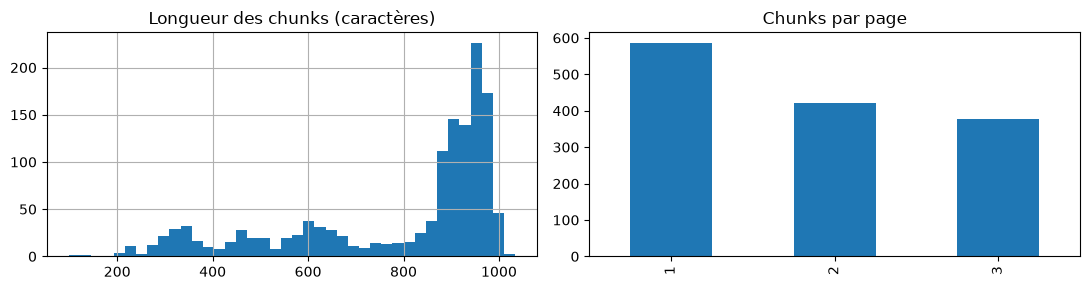

In [3]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
L.hist(bins=40, ax=ax[0]); ax[0].set_title("Longueur des chunks (caractères)")
pd.Series([d.metadata["page"] for d in chunks]).value_counts().sort_index().plot.bar(ax=ax[1]); ax[1].set_title("Chunks par page"); plt.tight_layout(); plt.show()

## 2.2 Choix de l'embedding
Évaluation **exacte** : on indexe les 250 chunks du dataset (identifiants connus) et on regarde si le bon chunk remonte pour chacune des 619 questions (hit@k, MRR).

In [4]:
docs250, ids250 = corpus_documents(ev["corpus"])
rows = []
for m in ["sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2", "intfloat/multilingual-e5-large", "BAAI/bge-m3", "Qwen/Qwen3-Embedding-0.6B"]:
    emb = LocalEmbeddings(m)
    store = build_store("cmp_" + m.split("/")[-1].replace(".", "_")[:40], docs250, emb, ids=[f"c{i}" for i in range(len(docs250))])
    rows.append({"modèle": m, **{k: round(v, 3) for k, v in exact_retrieval(store, ids250, ev["queries"], ev["relevant_docs"]).items()}})
    del emb, store; gc.collect(); torch.cuda.empty_cache()
emb_cmp = pd.DataFrame(rows); emb_cmp.to_csv("../resultats/comparaison_embeddings.csv", index=False); emb_cmp

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4460.43it/s]

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 4343.21it/s]

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 6231.82it/s]

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 310/310 [00:00<00:00, 4804.22it/s]

,modèle,hit@1,hit@3,hit@5,hit@10,mrr
0,sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2,0.176,0.294,0.401,0.528,0.268
1,intfloat/multilingual-e5-large,0.283,0.475,0.567,0.727,0.408
2,BAAI/bge-m3,0.307,0.498,0.622,0.796,0.443
3,Qwen/Qwen3-Embedding-0.6B,0.288,0.506,0.603,0.784,0.430


**Choix : `BAAI/bge-m3`** (multilingue, 568 M de paramètres, open weights) : meilleur MRR et meilleur hit@5/hit@10. Le modèle d'embeddings multilingue léger testé en baseline est nettement en retrait (le français financier lui échappe).

## 2.3 Reranking (second étage)
Les questions sont souvent génériques et plusieurs passages quasi identiques se concurrencent. Un **cross-encoder** (`bge-reranker-v2-m3`) reclasse les 20 meilleurs candidats de la recherche vectorielle.

In [5]:
emb = LocalEmbeddings(EMBED_MODEL)
store250 = build_store("eval_corpus250", docs250, emb, ids=[f"c{i}" for i in range(len(docs250))])
rr = Reranker(RERANK_MODEL)
class _RR:                       # même interface que le store, avec reranking
    def __init__(self, fetch): self.fetch = fetch
    def similarity_search(self, q, k): return rr.rerank(q, store250.similarity_search(q, k=self.fetch), k)
rows = [{"configuration": "bge-m3 seul", **exact_retrieval(store250, ids250, ev["queries"], ev["relevant_docs"])}]
for f in (20, 40):
    rows.append({"configuration": f"bge-m3 + reranker (top {f} → 10)", **exact_retrieval(_RR(f), ids250, ev["queries"], ev["relevant_docs"])})
rr_cmp = pd.DataFrame(rows).round(3); rr_cmp.to_csv("../resultats/comparaison_reranker.csv", index=False); rr_cmp

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 5962.15it/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 393/393 [00:00<00:00, 4409.91it/s]

,configuration,hit@1,hit@3,hit@5,hit@10,mrr
0,bge-m3 seul,0.307,0.498,0.622,0.796,0.443
1,bge-m3 + reranker (top 20 → 10),0.378,0.599,0.724,0.851,0.521
2,bge-m3 + reranker (top 40 → 10),0.380,0.599,0.732,0.874,0.525


Le reranker apporte un gain net (≈ +10 points de hit@5) ; passer de 20 à 40 candidats n'apporte presque rien pour un coût double → **20 candidats** retenus.

## 2.4 Réglage du découpage sur les PDF
On construit l'index depuis les **PDF** (notre découpage) et on mesure si le passage de référence du dataset est couvert (≥ 50 % de ses 4-grammes) par les k chunks récupérés. Les passages dégradés du dataset (absents de notre extraction) sont exclus.

⚠️ **Biais connu** : cette métrique favorise mécaniquement les gros chunks (un passage de ~750 caractères ne peut être couvert qu'en partie par un chunk de 500). Elle sert à écarter les mauvais réglages ; **l'arbitrage final se fait sur le score de bout en bout** (notebook 4, `resultats/comparaison_configs.csv`).

In [6]:
rows = []
for size, ov, hdr in [(500, 100, True), (900, 150, True), (900, 150, False), (1300, 200, True)]:
    docs = build_chunks(cat, chunk_size=size, chunk_overlap=ov, with_header=hdr)
    st = build_store(f"cmp_pdf_{size}_{int(hdr)}", docs, emb)
    texts = [d.page_content for d in docs]
    for use_rr in (False, True):
        fn = (lambda q, st=st: rr.rerank(q, st.similarity_search(q, k=20), 5)) if use_rr else (lambda q, st=st: st.similarity_search(q, k=5))
        r = pdf_retrieval(fn, ev["queries"], ev["relevant_docs"], ev["corpus"], texts)
        rows.append({"chunk": size, "overlap": ov, "en-tête": hdr, "reranker": use_rr, "n_chunks": len(docs), **{k: round(v, 3) if isinstance(v, float) else v for k, v in r.items()}})
chunk_cmp = pd.DataFrame(rows); chunk_cmp.to_csv("../resultats/comparaison_decoupage.csv", index=False); chunk_cmp

,chunk,overlap,en-tête,reranker,n_chunks,hit@1,hit@3,hit@5,n_evaluables,n_total
0,500,100,True,False,2446,0.199,0.359,0.426,577,619
1,500,100,True,True,2446,0.251,0.366,0.433,577,619
2,900,150,True,False,1384,0.326,0.497,0.565,577,619
3,900,150,True,True,1384,0.412,0.575,0.638,577,619
4,900,150,False,False,1384,0.385,0.541,0.598,577,619
5,900,150,False,True,1384,0.470,0.615,0.664,577,619
6,1300,200,True,False,929,0.345,0.518,0.612,577,619
7,1300,200,True,True,929,0.497,0.648,0.702,577,619


## 2.5 Intérêt de l'en-tête « produit » pour des questions **nommées**
Le dataset ne contient presque que des questions génériques : il ne peut pas mesurer l'intérêt de l'en-tête. On construit donc des questions **nommées** (« … pour le produit X ») à partir des mêmes questions et du PDF d'origine du passage ; succès = le bon passage **du bon document** est dans le top-k. (Test synthétique de robustesse, pas une métrique du dataset.)

In [7]:
pdf_texts = {p.name: "\n".join(t for _, t in load_pdf(p)) for p in list_pdfs()}
located = locate_sources(ev, pdf_texts)
rows = []
for hdr in (True, False):
    st = build_store(f"cmp_named_{int(hdr)}", build_chunks(cat, with_header=hdr), emb)
    fn = lambda q, st=st: rr.rerank(q, st.similarity_search(q, k=20), 5)
    rows.append({"en-tête produit": hdr, **{k: round(v, 3) if isinstance(v, float) else v for k, v in named_query_retrieval(fn, ev, located, cat).items()}})
named_cmp = pd.DataFrame(rows); named_cmp.to_csv("../resultats/comparaison_questions_nommees.csv", index=False); named_cmp

,en-tête produit,hit@1,hit@3,hit@5,n
0,True,0.648,0.778,0.815,577
1,False,0.227,0.324,0.360,577


## 2.6 Index final (ChromaDB persistant)

In [8]:
final = build_store(COLLECTION, build_chunks(cat), emb)
print(f"Collection « {COLLECTION} » : {final._collection.count()} chunks, persistée dans {CHROMA_DIR}")
for d in final.similarity_search("Quels sont les frais d'entrée du fonds Carmignac Sécurité ?", k=3):
    print("\n", d.metadata["source"], "p.", d.metadata["page"], "\n", d.page_content[:300])

Collection « dic_pdf » : 1384 chunks, persistée dans /home/jeremie/projet_rag/vectorstore

 Carmigac.pdf p. 2 
 Document : Carmignac Sécurité PART AW EUR ACC (Carmignac Gestion)
Frais
Les frais et commissions acquittés servent à couvrir les coûts d'exploitation du fonds, y compris les coûts de commercialisation et de distribution des parts. Ces frais réduisent la croissance potentielle
des investissements.
Fr

 Carmigac.pdf p. 2 
 Document : Carmignac Sécurité PART AW EUR ACC (Carmignac Gestion)
Il n'y a pas de commission de performance pour ce fonds.
Les frais d'entrée et de sortie affichés constituent les maxima applicables et sont
acquis au distributeur. Dans certains cas des frais inférieurs peuvent être appliqués, vous p

 Carmigac.pdf p. 1 
 Document : Carmignac Sécurité PART AW EUR ACC (Carmignac Gestion)
et/ou non coordonnés dans la limite de 10% de l'actif net.
2 Du fait de l'exposition du fonds sur les marchés de taux de la zone euro, la durée
recommandée de placement est de 